### 회귀 알고리즘 : 선형 회귀

In [15]:
# 라이브러리
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

In [16]:
# 농어 길이 데이터
perch_length = np.array([
    8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7,
    19.0, 19.6, 20.0, 21.0, 21.0, 21.0, 21.3,
    22.0, 22.0, 22.0, 22.0, 22.0, 22.5, 22.5,
    22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0,
    25.6, 26.5, 27.3, 27.5, 27.5, 27.5, 28.0,
    28.7, 30.0, 32.8, 34.5, 35.0, 36.5, 36.0,
    37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0,
    40.0, 40.0, 42.0, 43.0, 43.0, 43.5, 44.0
])

# 농어 무게 데이터
perch_weight = np.array([
    5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0,
    80.0, 85.0, 85.0, 110.0, 115.0, 125.0,
    130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0,
    145.0, 188.0, 180.0, 197.0, 218.0, 300.0,
    260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0,
    690.0, 900.0, 650.0, 820.0, 850.0, 900.0,
    1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0
])

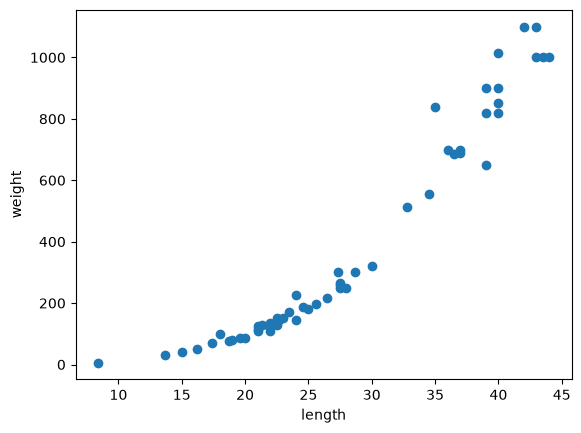

In [17]:
# 농어 데이터 시각화
plt.scatter(perch_length, perch_weight)
plt.xlabel('length')
plt.ylabel('weight')
plt.show() 

In [18]:
# 데이터 분리
train_input, test_input, train_target, test_target = train_test_split(
    perch_length, perch_weight, random_state=42
)

print(train_input.shape, test_input.shape)

(42,) (14,)


In [19]:
# 2차원 배열로 변환
train_input = train_input.reshape(-1, 1)
test_input = test_input.reshape(-1, 1)
# -1 : 전체 데이터 개수에 맞춰 행의 수를 자동으로 결정
# 1: 특성이 농어 길이 하나이므로 열의 수는 1로 지정

print(train_input.shape, test_input.shape)

(42, 1) (14, 1)


#### 기존 회귀 모델의 성능 확인 (K-최근접 회귀)

In [20]:
# 기존 회귀 모델의 성능 확인
# K-최근접 회귀 모델
knr = KNeighborsRegressor()
knr.fit(train_input, train_target)

print(knr.score(train_input, train_target))
print(knr.score(test_input, test_target))

0.9698823289099254
0.992809406101064


In [21]:
# 이웃 개수 3개로 지정
knr = KNeighborsRegressor(n_neighbors=3)
knr.fit(train_input, train_target)

print(knr.predict([[50]]))

[1033.33333333]


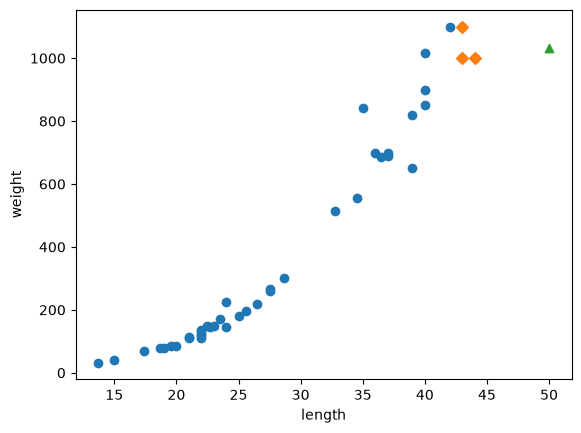

In [22]:
# 가장 가까운 이웃 확인하기
# 50cm 농어의 이웃 검색
distances, indexes = knr.kneighbors([[50]])

# 훈련 데이터 산점도
plt.scatter(train_input, train_target)

# 가까운 이웃 3개 표시
plt.scatter(
    train_input[indexes],
    train_target[indexes],
    marker='D'
)

# 길이가 50cm인 농어 표시
plt.scatter(50, 1033, marker='^')

plt.xlabel('length')
plt.ylabel('weight')
plt.show()

In [23]:
# 길이가 100cm인 농어의 무게 예측
print(knr.predict([[100]]))

[1033.33333333]


#### 선형 회귀
주어진 데이터의 관계를 가장 작 나타내는 선형방정식을 찾는 것이다
특성이 하나이면 직선의 방정식 형태로 나온다

In [24]:
# 선형 회귀 모델 생성
lr = LinearRegression()

# 모델 훈련
lr.fit(train_input, train_target)

# 50cm 농어 무게 예측
print(lr.predict([[50]]))

[1241.83860323]


In [25]:
# 기울기와 절편 확인하기
print(lr.coef_, lr.intercept_)

[39.01714496] -709.0186449535477


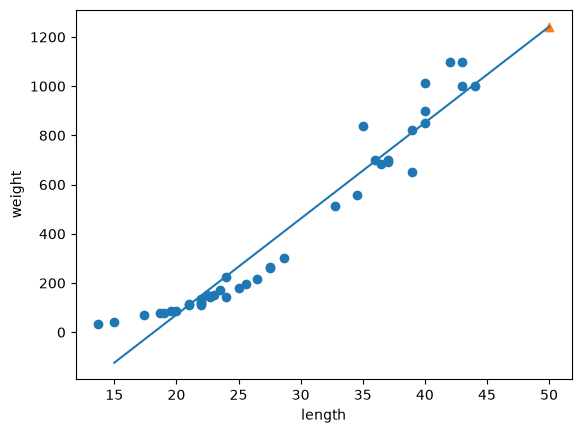

In [26]:
# 훈련 데이터 산점도
plt.scatter(train_input, train_target)

# 학습한 직선 그리기
plt.plot(
    [15, 50],
    [15 * lr.coef_[0] + lr.intercept_,
     50 * lr.coef_[0] + lr.intercept_]
)

# 50cm 농어 예측값 표시
plt.scatter(50, 1241.8, marker='^')

plt.xlabel('length')
plt.ylabel('weight')
plt.show()

In [27]:
# 선형 회귀 성능 평가
print(lr.score(train_input, train_target))
print(lr.score(test_input, test_target))

0.939846333997604
0.8247503123313558


#### 다항회귀
선형회귀가 1차함수라면 다항회귀는 2차방정식

In [28]:
# 다항 특성 만들기
# 훈련 데이터의 길이 제곱과 길이를 결합
train_poly = np.column_stack(
    (train_input ** 2, train_input)
)

# 테스트 데이터도 동일하게 변환
test_poly = np.column_stack(
    (test_input ** 2, test_input)
)

print(train_poly.shape)
print(test_poly.shape)

(42, 2)
(14, 2)


In [ ]:
# 다항 회귀 모델 다시 훈련하기
lr = LinearRegression()

# 다항 특성으로 모델 훈련
lr.fit(train_poly, train_target)

# 50cm 농어의 무게 예측
print(lr.predict([[50**2, 50]]))

# 계수와 절편 확인
print(lr.coef_, lr.intercept_)

#y=1.0143x^2-21.5579x+116.0502}

[1573.98423528]
[  1.01433211 -21.55792498] 116.0502107827827


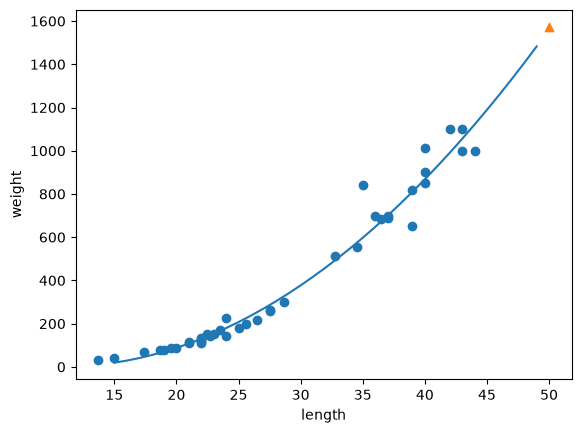

In [30]:
# 다항회귀 그래프 출력
# 15부터 49까지 정수 배열 생성
point = np.arange(15, 50)

# 훈련 데이터 산점도
plt.scatter(train_input, train_target)

# 2차 방정식 그래프
plt.plot(
    point,
    1.01 * point**2 - 21.6 * point + 116.05
)

# 50cm 농어 예측값 표시
plt.scatter([50], [1574], marker='^')

plt.xlabel('length')
plt.ylabel('weight')
plt.show()

In [31]:
# 다항 회귀 모델 성능 평가
print(lr.score(train_poly, train_target))
print(lr.score(test_poly, test_target))

0.9706807451768623
0.9775935108325122
